In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder, FunctionTransformer
from sklearn.model_selection import StratifiedKFold, train_test_split
from category_encoders import CountEncoder
from funcs import datetime_processing_func
from sklearn.model_selection import cross_validate

In [2]:
df = pd.read_csv("./fraudTrain.csv")
df_test = pd.read_csv("./fraudTest.csv")

In [3]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [4]:
pipe_metrics = joblib.load("model.joblib")

In [5]:
pipe_prev = pipe_metrics["pipeline"]

In [6]:
prev_metrics = pipe_metrics["metrics"]

In [7]:
pipe_prev

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('datetime_proc', ...), ('encoders', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function dat...0015A6F787320>
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",{'date_feature': 'trans_date_trans_time'}
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only

In [8]:
from imblearn.over_sampling import SMOTE, SMOTEN, SMOTENC
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as Imb_Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier

In [9]:
smote = SMOTE(random_state = 42, sampling_strategy = 0.1)
smoten = SMOTEN(random_state = 42, sampling_strategy = 0.1)
smotenc = SMOTENC(categorical_features = ["gender", "merchant", "category", "job", "state"], random_state = 42, sampling_strategy = 0.1)

In [10]:
pipe = Imb_Pipeline([])
pipe.steps = clone(pipe_prev).steps

In [11]:
type(pipe)

imblearn.pipeline.Pipeline

In [18]:
cv= StratifiedKFold(n_splits= 5, shuffle = True, random_state = 42)

personal_info = ["first", "last", "dob", "cc_num", "street", "city", "zip", "dob", "trans_num", "is_fraud", "Unnamed: 0"]

y_train = df["is_fraud"]
X_train = df.drop(personal_info, axis =1)
X_test = df_test.drop(personal_info, axis =1)
y_test = df_test["is_fraud"]

In [19]:
X_train_proc = pipe[0].fit_transform(X_train, y_train)

X_train_proc, y_train_proc = smotenc.fit_resample(X_train_proc,y_train)

X_train_proc = pipe[1:].fit_transform(X_train_proc, y_train_proc)

X_test_proc = pipe.transform(X_test)

In [20]:
X_train_proc

,gender_M,merchant,category,job,state,amt,lat,long,city_pop,unix_time,merch_lat,merch_long,Date,Time
0,0.0,0.159190,0.053907,0.010885,0.073900,4.970000,36.078800,-81.178100,3495,1325376018,36.011293,-82.048315,1,0
1,0.0,0.180917,0.111666,0.047426,0.085599,107.230000,48.887800,-118.210500,149,1325376044,49.159047,-118.186462,1,0
2,1.0,0.038283,0.067810,0.142698,0.043183,220.110000,42.180800,-112.262000,4154,1325376051,43.150704,-112.154481,1,0
3,1.0,0.059643,0.097773,0.115986,0.046288,45.000000,46.230600,-112.113800,1939,1325376076,47.034331,-112.561071,1,1
4,1.0,0.058095,0.057600,0.000000,0.109358,41.960000,38.420700,-79.462900,99,1325376186,38.674999,-78.632459,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1418080,0.0,0.007735,0.082028,0.072725,0.086138,169.221912,42.937300,-87.994300,13973,1346776669,43.348088,-87.737244,247,997
1418081,1.0,0.075399,0.095299,0.082873,0.081658,259.779407,42.691100,-71.160500,76383,1337998955,42.212151,-70.771143,145,553
1418082,0.0,0.176557,0.111666,0.082209,0.084857,386.614283,39.080133,-84.551858,639,1355283941,38.935226,-85.226876,346,224
1418083,0.0,0.061749,0.111666,0.041870,0.101541,127.339744,43.062200,-77.221800,9565,1368840241,43.688121,-76.941515,138,959


In [21]:
model = LGBMClassifier()

In [22]:
model.fit(X_train_proc, y_train_proc)

result_metrics_1 = cross_validate(model, X_test_proc, y_test, cv = cv, n_jobs = 10, scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"])

[LightGBM] [Info] Number of positive: 128916, number of negative: 1289169
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011177 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3056
[LightGBM] [Info] Number of data points in the train set: 1418085, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.090909 -> initscore=-2.302592
[LightGBM] [Info] Start training from score -2.302592


In [23]:
result_metrics_1

{'fit_time': array([4.61449146, 4.28541541, 4.38074422, 4.67682123, 4.2023437 ]),
 'score_time': array([0.19702363, 0.28870797, 0.30122828, 0.189533  , 0.2481842 ]),
 'test_accuracy': array([0.99621212, 0.99538437, 0.99604117, 0.99599619, 0.99648201]),
 'test_precision': array([0.50884956, 0.42553191, 0.48764045, 0.48479087, 0.53861789]),
 'test_recall': array([0.53613054, 0.55944056, 0.50582751, 0.59440559, 0.61771562]),
 'test_f1': array([0.52213394, 0.48338369, 0.49656751, 0.53403141, 0.57546145]),
 'test_roc_auc': array([0.83555248, 0.84465373, 0.80201588, 0.89062356, 0.90776939])}

In [24]:
result_metrics_1 = {key : np.mean(val) for key, val in result_metrics_1.items()}

In [25]:
models_diff = {}

for key, vl in result_metrics_1.items():
    models_diff[key] = vl - prev_metrics[key]

<Axes: >

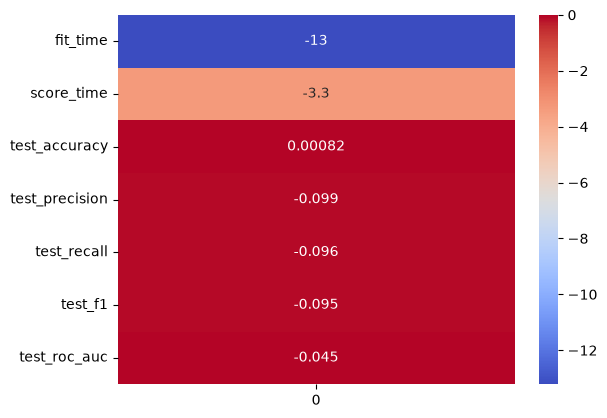

In [26]:
sns.heatmap(pd.Series(models_diff).to_frame(), cmap = "coolwarm", annot = True)

Судя по метрикам стало хуже, дисбаланс создал шум и на тестовых данных результат обучения с шумом продемонстрировал плохой результат

In [27]:
cv = StratifiedKFold(n_splits = 5, shuffle =True , random_state =42)

personal_info = ["first", "last", "dob", "cc_num", "street", "city", "zip", "dob", "trans_num", "is_fraud", "Unnamed: 0"]

cat = ["cc_num", "merchant", "category", "first", "last", "gender", "street", "city", "state", "zip", "job", "is_fraud"]
num = ["amt", "first", "last", "lat", "long", "city_pop", "dob", "trans_num", "unix_time", "merch_lat", "merch_long", "Date", "Time"]

cat = [col for col in cat if col not in personal_info]
num = [col for col in num if col not in personal_info]

df_learning = df.drop(personal_info, axis =1)
target = df["is_fraud"]

X_train_proc = pipe[0].fit_transform(X_train, y_train)

X_train_cat, y_train_cat = smoten.fit_resample(X_train_proc[cat],y_train)
X_train_num , y_train_num = smote.fit_resample(X_train_proc[num],y_train)

X_train_proc = pd.concat([X_train_cat, X_train_num], axis = 0)
y_train_proc = pd.concat([y_train_cat, y_train_num], axis = 0)

X_train_proc = pipe[1:].fit_transform(X_train_proc, y_train_proc)

X_test_proc = pipe.transform(X_test)

In [28]:
model.fit(X_train_proc, y_train_proc)

result_metrics_2 = cross_validate(model, X_test_proc, y_test, cv = cv, n_jobs = 10, scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"])

[LightGBM] [Info] Number of positive: 257832, number of negative: 2578338
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020017 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3012
[LightGBM] [Info] Number of data points in the train set: 2836170, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.090909 -> initscore=-2.302592
[LightGBM] [Info] Start training from score -2.302592


In [29]:
result_metrics_2 = {key : np.mean(val) for key, val in result_metrics_2.items()}

In [30]:
models_diff = {}

for key, vl in result_metrics_2.items():
    models_diff[key] = vl - prev_metrics[key]

<Axes: >

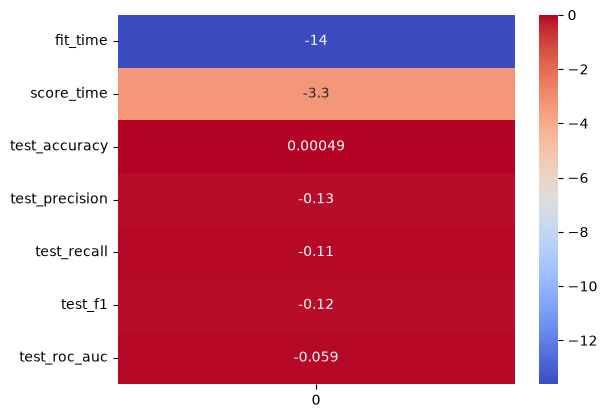

In [31]:
sns.heatmap(pd.Series(models_diff).to_frame(), cmap = "coolwarm", annot = True)

Результат с раздельными значениями после раздельного применения smote и smoten даже хуже чем при smotenc

In [32]:
def to_categorical_func(df, cols):
    df = df.astype('category')
    return df

In [33]:
to_categorical = FunctionTransformer(to_categorical_func, kw_args = {"cols": ['merchant', 'category', 'gender', 'state', 'job']})
pipe = clone(pipe_prev)
pipe.steps.pop(1)
pipe.steps.append(("to_categorical", to_categorical))

In [34]:
cv = StratifiedKFold(n_splits = 5, shuffle =True , random_state =42)

personal_info = ["first", "last", "dob", "cc_num", "street", "city", "zip", "dob", "trans_num", "is_fraud", "Unnamed: 0"]

X_train_proc = pipe.fit_transform(X_train, y_train)

X_test_proc = pipe.transform(X_test)

In [35]:
model.fit(X_train_proc, y_train)

result_metrics_3 = cross_validate(model, X_test_proc, y_test, cv = cv, n_jobs = 10, scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"])

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Number of positive: 7506, number of negative: 1289169
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010214 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19956
[LightGBM] [Info] Number of data points in the train set: 1296675, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.005789 -> initscore=-5.146050
[LightGBM] [Info] Start training from score -5.146050


In [36]:
result_metrics_3

{'fit_time': array([6.58217072, 6.49906707, 6.50748324, 6.32738972, 6.47667742]),
 'score_time': array([1.1713357 , 1.16683865, 1.18709254, 0.95021892, 1.17756176]),
 'test_accuracy': array([0.99753473, 0.99750774, 0.99753473, 0.9976337 , 0.99760669]),
 'test_precision': array([1.        , 0.98717949, 0.98742138, 0.98823529, 0.98224852]),
 'test_recall': array([0.36130536, 0.35897436, 0.36596737, 0.39160839, 0.38694639]),
 'test_f1': array([0.53082192, 0.52649573, 0.53401361, 0.56093489, 0.55518395]),
 'test_roc_auc': array([0.99350471, 0.99279609, 0.99205291, 0.99413711, 0.99475991])}

In [37]:
result_metrics_3 = {key : np.mean(val) for key, val in result_metrics_3.items()}

In [38]:
models_diff = {}

for key, vl in result_metrics_3.items():
    models_diff[key] = vl - prev_metrics[key]

<Axes: >

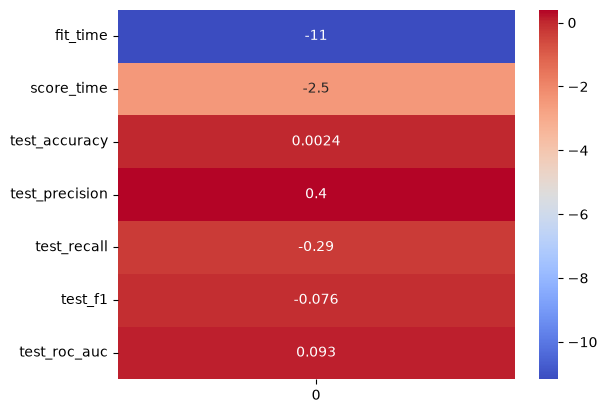

In [39]:
sns.heatmap(pd.Series(models_diff).to_frame(), cmap = "coolwarm", annot = True)

Precision вырос, для данной модели антифрод, это не плохой результат, точность в вопросе антифрод систем это важно, но если учитывать, что в моделе есть дисбаланс, то вероятно модель предсказала на 1, 2 фрод транзакции больше

In [40]:
y_train = df["is_fraud"]
X_train = df.drop(personal_info, axis =1)
X_test = df_test.drop(personal_info, axis =1)
y_test = df_test["is_fraud"]

In [41]:
pipe1 = clone(pipe_prev)
pipe1.steps.append(("to_categorical", to_categorical))
y_test_no_enc = y_test 

X_train_proc = pipe1.fit_transform(X_train, y_train)
X_test_proc = pipe1.transform(X_test)

y_test_w_enc = model.predict(X_test_proc)

In [42]:
check_df = pd.DataFrame({"no_enc": y_test_no_enc.to_numpy(), "with_enc": y_test_w_enc},index=y_test.index)
check_df = check_df.join(df["is_fraud"])
check_df

,no_enc,with_enc,is_fraud
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
...,...,...,...
555714,0,0,0
555715,0,0,0
555716,0,0,0
555717,0,0,0


In [43]:
check_df["mask"] = (check_df["no_enc"] == check_df["with_enc"])
check_df[check_df["mask"] == False] 
check_df[(check_df["mask"] == False) & (check_df["is_fraud"] == 1)]

,no_enc,with_enc,is_fraud,mask
18142,1,0,1,False
26363,1,0,1,False
26397,1,0,1,False
36126,1,0,1,False
36187,1,0,1,False
53893,1,0,1,False
85967,1,0,1,False
118079,1,0,1,False
118168,1,0,1,False
134048,1,0,1,False


In [44]:
check_df[(check_df["mask"] == False) & (check_df["is_fraud"] == 1)].shape

(14, 4)

Ошибся, бывает, как видно из результата, 14 строк после энкодинга были обозначены как не фрод транзакции, хотя являются таковыми, в конечном пайплайне уберу энкодеры

In [45]:
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('datetime_proc', ...), ('to_categorical', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['trans_date_trans_time','merchant','category',...,'unix_time','merch_lat', 'merch_long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function dat...0015A6F787320>
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",{'date_feature': 'trans_date_trans_time'}
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [46]:
dumper = {
    "metrics" : result_metrics_3,
    "pipeline" : pipe
}
joblib.dump(dumper, f"results_imp.joblib")

['results_imp.joblib']